<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    LNDb - Lung Nodule Database
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    A datased based on LIDC-IDRI
  </h3>

  <p>
   The LNDb was developed as an external dataset complimentary to LIDC-IDRI. There are a few important differences between the two... While LIDC-IDRI is a project shared between 7 institutions, LNDb is a smaller dataset, belonging to a single institution - Centro Hospitalar e Universitário de São João (CHUSJ) in Porto.
  </p>
  <p>
   LNDb contains 294 CT scans - about a quarter of the size of LIDC-IDRI, and its classification method is different as well: it uses a single-blind methodology (a radiologist would read the scan once and no consensus or review between the radiologists was performed), instead of having multiple radiologists reading the same scan. This might cause a noticeable distinction in classification pattern for each radiologist; but, unlike LIDC-IDRI, the 5 participant radiologists are identified uniformly throughout the dataset as R1, R2, R3, R4 and R5.
  </p>
  <p>
   The variability in acquisition parameters is significantly lower in LNDb, as well as the subjective characterization of nodules. LNDb is overall a more clinically realistic dataset.
   </p>
  
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Initial Data Analysis & Pre-Processing
  </h3>

  <p>
    To access LNDb's auxiliary functions, which will help us to visualize, understand and manipulate data, we must import the script <strong>'utils.py'</strong> and other scripts made available with the download of the dataset.
  </p>
  <p>
    The first step in our analysis of the dataset is to ensure that we can read the MetaImage <strong>.mhd/.raw</strong> medical image files - both the Computerized Tomography (CT) data and the segmentation masks are in this format. The file <strong>'utils.py'</strong> includes routines based on the SimpleITK library that allow us to... 
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Load the 3D CT images and the nodule masks.</li>
    <li style="margin-bottom: 8px;">Extract the metadata from the medical images, such as the pixel/voxel spacing, the origin and the orientation matrix of the CT.</li>
  </ol>
  <p>
    We also want to match scan slices to nodule coordinates. Thus, we have created a reusable function <strong>read_nods_in_scan</strong> which, for one scan metadata file LNDb-XXXX.mhd, and its corresponding image LNDb-XXXX.raw, extracts the necessary information for coordinate conversion from milimeters into pixels/voxels and vice-versa. This is possible using the origin, the spacing and transformation matrix of the scan. 
  </p>
  <p>
    This function also reads the nodule coordinates, in milimeters, and converts them to image coordinates, in pixel / cut indexes, using the origin and transformation origin of the corresponding scan. This way, we can associate these coordinates with the scan image. It also repeats the process for the nodule mask. So, we are able to quickly visualize every node and its mask in each CT Scan!
  </p>
</div>

In [ ]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from contextlib import redirect_stdout
root_path = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(root_path) not in sys.path: sys.path.append(str(root_path))
# Os scripts do LNDb importam-se entre si sem prefixo (ex: 'from utils import readCsv'),
# por isso a própria pasta src/lndb_utils também tem de estar no sys.path
lndb_utils_path = root_path / 'src' / 'lndb_utils'
if str(lndb_utils_path) not in sys.path: sys.path.append(str(lndb_utils_path))

from src.lndb_utils import utils
from src.lndb_utils.readNoduleList import nodEqDiam
from src.lndb_utils.calcFleischner import calcFleischner

def find_file(name, base_folder="../data"):
    results = list(Path(base_folder).rglob(name))
    if not results:
        raise FileNotFoundError(f"File '{name}' not found in '{base_folder}'.")
    return str(results[0])

def read_nods_in_scan(LNDb_id, nods_table): #Reads one CT Scan and returns array, metadata and scan nodules with converted coordinates.
    path_mhd = find_file(f'LNDb-{LNDb_id:04d}.mhd')
    scan, spacing, origin, transfmat = utils.readMhd(path_mhd) # read metadata from scan, necessary for coordinate conversion
    transfmat_toimg, transfmat_toworld = utils.getImgWorldTransfMats(spacing, transfmat) #
    nods_scan = nods_table[nods_table['LNDbID'] == LNDb_id].copy()

    coords_img = []
    masks_img = []
    for _, line in nods_scan.iterrows():
        xyz_world = np.array([line['x'], line['y'], line['z']])
        xyz_img = utils.convertToImgCoord(xyz_world, origin, transfmat_toimg)
        coords_img.append(xyz_img)
        try: mask_mhd = find_file(f"LNDb-{LNDb_id:04d}_rad{int(line['RadID'])}.mhd")
        except FileNotFoundError: continue
        mask, _, _, _ = utils.readMhd(mask_mhd)
        masks_img.append(mask)

    nods_scan['x_img'] = [c[0] for c in coords_img]
    nods_scan['y_img'] = [c[1] for c in coords_img]
    nods_scan['z_img'] = [c[2] for c in coords_img]
    nods_scan['mask'] = [m for m in masks_img]

    return scan, spacing, origin, nods_scan

ct_scan_id = 1
nods_table = pd.read_csv(find_file('trainNodules.csv'))
scan, spacing, origin, nods_scan = read_nods_in_scan(ct_scan_id, nods_table)

print(f"The CT Scan {ct_scan_id} has...\n  -> dimensions {scan.shape}\n  -> origin {origin}\n  -> spacing {spacing}\n")
print(f"For this scan, we have {len(nods_scan)} findings:")
print(nods_scan[['LNDbID', 'RadID', 'FindingID', 'x_img', 'y_img', 'z_img']])

The CT Scan 1 has...
  -> dimensions (328, 512, 512)
  -> origin (-158.1962890625, -309.1962890625, -297.5)
  -> spacing (0.607421875, 0.607421875, 1.0)

For this scan, we have 4 findings:
   LNDbID  RadID  FindingID  x_img  y_img  z_img
0       1      1          1  187.0  313.0  260.0
1       1      1          2  303.0  300.0  252.0
2       1      2          1  188.0  314.0  260.0
3       1      3          1  188.0  312.0  260.0


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    By the shape of the scan array, we can conclude that it has 328 cuts of 512x512 pixels. The voxel spacing (0.607, 0.607, 1.0)mm shows that the volume <strong>is not isotropic</strong> because the plane resolution is thinner than in between cuts. This is something to have in mind if we decide to resample into a uniform spacing before feature extraction - this probably makes the most sense. 
  </p>
  <div style="background-color: #c25719; padding: 2px 10px; border-radius: 0px; margin: 0px -10px;">
    <strong style="color: #1967d2;">Note:</strong> An isotropic volume implies that the spacing between voxels is equal in all directions (x, y, z) - in other words, each voxel is shaped like a perfect cube.
  </div>
  <p>
    Lastly, the origin indicates the coordinate of the word corresponding to the volume corner, necessary to convert nodule coordinates in further steps.
  </p>
  <p>
    Now, we must confirm visually the coordinate conversion by showing the exact cut where the nodule was annotated, with a red <strong>X</strong> in its position. Below, there is the side-by-side comparison of the original image and the annotated image with its nodules.
  </p>
</div>

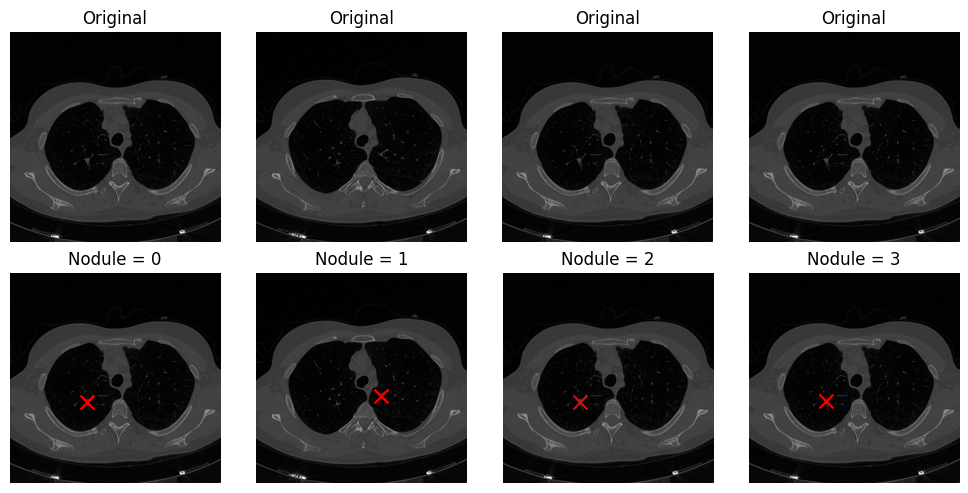

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(len(nods_scan)):
    axes[0][i].imshow(scan[int(nods_scan['z_img'].iloc[i])], cmap='gray')
    axes[0][i].set_title(f"Original")
    axes[0][i].axis("off")  # Hides x and y tick marks
    axes[1][i].imshow(scan[int(nods_scan['z_img'].iloc[i])], cmap='gray')
    axes[1][i].set_title(f"Nodule = {i}")
    axes[1][i].scatter(nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], c='red', marker='x', s=100)  # marca a posição do nódulo
    axes[1][i].axis("off")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    By comparing the original CT slice with the annotated nodule, we confirm that it does, indeed, correspond to the location of a nodule. However, for this CT Scan, we also understand that nodules 0, 2 and 3 are the same - they were simply marked by 3 different radiologists. This can be confirmed both by their 'FindingID' and by taking a closer look at the nodules. The <strong>'utils.py'</strong> module has a function which extracts a small region of an image (typically 80x80x80 voxels) surrounding a central point. This makes it very easy to get a centered image of each nodule!
  </p>
</div>

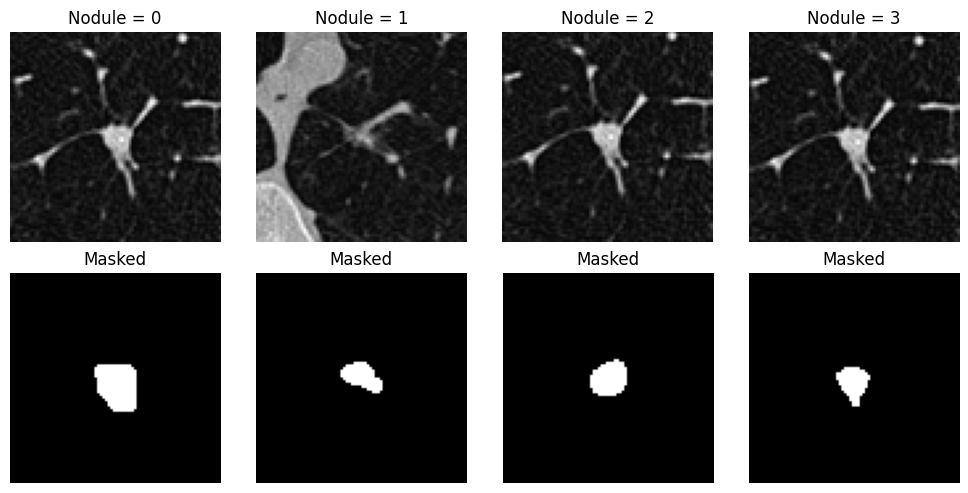

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(len(nods_scan)):
    cube = utils.extractCube(scan, spacing, (nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], nods_scan['z_img'].iloc[i]))
    mask_cube = utils.extractCube(nods_scan['mask'].iloc[i], spacing, (nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], nods_scan['z_img'].iloc[i]))
    axes[0][i].imshow(cube[cube.shape[0]//2], cmap='gray')
    axes[0][i].set_title(f"Nodule = {i}")
    axes[0][i].axis("off")  # Hides x and y tick marks
    axes[1][i].imshow(mask_cube[mask_cube.shape[0]//2], cmap = 'gray')
    axes[1][i].set_title(f"Masked")
    axes[1][i].axis("off")

plt.tight_layout()
plt.show() 
# Adjust spacing and display


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    And, as it is very clear now, there are 3 repeated nodules. This repetitions happens because the file <strong>'trainNodules.csv'</strong> has an entry for each finding made by a radiologist. So, if many radiologists annotate the same nodule, there are many rows corresponding to that node in the file. The radiologists annotated the nodule's mask pretty differently, even if it is exactly the same nodule. This is, actually, an important part of our pre-processing: we must decide how to deal with different subjective annotations for the same nodule.
  </p>
  <p>
    This repetition of the same nodule also happens in another file available in our dataset: <strong>chars_trainNodules.csv</strong>. In fact, these two complement eachother! The first stores the (x, y, z) coordinates of each finding, the nodule classification (nodule / non-nodule) and the volume and texture (necessary for calculating Fleischner Score). The second stores the subjective characteristics of each nodule (calcification, internal structure, malignancy, ...). So, it is a good idea to join them in one single file.
  </p>
  <p>
    However, there is a small detail to take into account - there is disparity line-wise in these files. <strong> chars_trainNodules.csv</strong> contains records from all 5 radiologists, while <strong>trainNodules.csv</strong> only contains records from radiologists 1, 2 and 3. This happens because, in the second file, the 'RadID' is relative to the CT Scan, and not to the overall ID of the radiologist. This can be handled by simply merging both tables while deleting duplicate columns and keeping the correct 'RadID_Real' relative to the overall radiologist ID instead of to the CT scan radiologist ID.
  </p>
</div>

In [ ]:
char_train= pd.read_csv(find_file('chars_trainNodules.csv'))
train = pd.read_csv(find_file('trainNodules.csv'))

# Positional join: only valid if lines correspond to the same finding
assert len(train) == len(char_train)
assert (train[['LNDbID', 'FindingID']].values == char_train[['LNDbID', 'FindingID']].values).all()

combined_df = pd.concat([train, char_train.drop(columns=['LNDbID', 'FindingID']).rename(columns={'RadID': 'RadID_real'})],axis=1,)
combined_df['RadID_real'] = combined_df['RadID_real'].astype(int)

# 'outer' keeps all entries, 'inner' keeps only nodules present in both.
#combined_df = pd.merge(train, char_train, on=['LNDbID', 'RadID', 'FindingID'], how="outer")

print(combined_df.shape)
print(" | ".join(combined_df.columns))

(1527, 18)
LNDbID | RadID | FindingID | x | y | z | Nodule | Volume | Text | RadID_real | calcification | internalStructure | lobulation | malignancy | margin | sphericity | spiculation | subtlety


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Now, let us take a moment to understand the meaning of each column in our dataframe. We must have a clear understanding of our data so that we can make better processing choices and achieve better accuracy on our final predictions.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Each line corresponds to a finding <strong style="color: #c25719;">FindingID</strong> marked by a radiologist <strong style="color: #c25719;">RadID_Real</strong> in a scan <strong style="color: #c25719;">LNDbID</strong>.</li>
    <li style="margin-bottom: 8px;">We have the coordinates <strong style="color: #c25719;">x</strong>, <strong style="color: #c25719;">y</strong> and <strong style="color: #c25719;">z</strong> of our finding.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Nodule</strong> is 1 if the finding is a nodule, and 0 if it is not.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Volume</strong> is the physical 3D volume of the annotated pulmonary lesion, measured in cubic millimeters.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Text</strong> refers to the texture of the nodule, and, combined with Volume, allows for Fleischner Score calculations.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Calcification</strong> refers to calcium deposits inside the nodule. Calcifications can be concentric rings, as well as off-centered or tiny scattered specks.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Internal Structure</strong> describes what the inside of the nodule consists of; specifically, its tissue density and components. It can be <strong>solid</strong>, <strong>subsolid</strong>, <strong>part-solid</strong>... Also, <strong>fat</strong> inside a nodule strongly favors a benign hamartoma, while <strong>cavitations</strong> warrant careful evaluation.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Lobulation</strong> refers to a wave-like outer contour instead of a smooth circle. Lobulated margins occur due to uneven growth rates in different parts of the nodule.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Malignancy</strong> categorizes on a scale from 1 to 5 the overall probability that the nodule is cancerous based on size, growth rate and physical features.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Margin</strong> is the general appearance of the border where the nodule meets normal lung tissue. It can be <strong>smooth/well-defined</strong> or <strong>ill-defined/irregular</strong>.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Sphericity</strong> measures how closely the nodule resembles a 3D sphere versus an elongated or flat shape.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Spiculation</strong> refers to strands or "spikes" radiating outward from the edge of the nodule into surrounding lung tissue, giving it a starburst appearance.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Subtlety</strong> indicates how easy or difficult the nodule is to visually distinguish from surrounding structures (like normal blood vessels, chest wall, or diaphragm).</li>
  </ul>
  <p>
    However, these two files that we have just merged together are not the only ones - we have yet another pair of files from where we can extract useful information: <strong>allNods.csv</strong> and <strong>trainNodules_gt.csv</strong>. Even if their names do not seem to be related (in contratry to the previous pair of files), they are actually structured in a similar manner: both of them are grouped by <i>nodule</i> instead of <i> radiologist finding</i>. This seems much more interesting to our project, since we must evaluate independent nodules instead of radiologist findings.
  </p>
  <p>
    Actually, combining these two gives us pretty much the same information that we have previously acquired, but the values are the mean of the radiologists. We could simply consider the mean for our prediction model, but it might be interesting to study independent radiologists' classifications and tendencies as another important feature. So, let us merge these two together and analyse the new information we have.
  </p>
</div>

In [ ]:
all_nods = pd.read_csv(find_file('allNods.csv'))
gt_nods = pd.read_csv(find_file('trainNodules_gt.csv'))

new_cols = set([a.lower() for a in all_nods.columns]) - set([a.lower() for a in combined_df.columns])
print(f"The table all_nods has new information:\n{', '.join(new_cols)}\nIt has {all_nods.shape[0]} rows and {all_nods.shape[1]} columns in total.")

The table all_nods has new information:
lobe, textquestion, diam_text, textinstanceid, where, texture, diameq_rad, radfinding, pos_text, nodtype, caract_text
It has 1234 rows and 26 columns in total.


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The column <strong>'Where'</strong> refers to whether the nodule was annotated by CT Scan, by text report, or both. As we are interested in classifying nodules using their scan images and masks, and as the text reports do not give us (x, y, z) coordinates or, in most cases, subjective characterizations to work with, it is a good choice to remove those lines.
  </p>
  <p>
    There are also a few columns which do not give us useful predictive information: <strong>'TextInstanceID'</strong> simply guides to a certain instance in a text report; other columns are also relative to the text report, but their information might be relevant to consider (such as <strong>'diam_text'</strong> or <strong>'caract_text'</strong>, which have been classified in the CT Scan, but their text values can add value to our predictions by comparison). 
  </p>
  <p>
    Let us explain briefly the meaning of the new information that has been added from this file:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">RadFinding</strong> is the equivalent to the <strong style="color: #c25719;">FindingID</strong> in our previous files, and <strong style="color: #c25719;">FindingID</strong> in this file is actually the individual node ID for each CT Scan.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">DiamEq_Rad</strong> represents the equivalent spherical diameter of a nodule (measured in millimeters), as segmented by a specific radiologist.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Texture</strong> is equivalent to previously studied column <strong>'Text'</strong>.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Lobe</strong> gives us information about which part of the lung it is located (1 'Left Upper Lobe', 2 'Left Lower Lobe', 3 'Right Upper Lobe', 4 'Middle Lobe', 5 'Right Lower Lobe').</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">TextQuestion</strong> gives us information about uncertainty of the radiologist in the text report.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">PosText</strong> gives additional details about nodule location, from text report.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Diam_Text</strong> is the diameter calculated in the text report.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Nod_Type</strong> classifies type of nodule in the text report.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Caract_Text</strong> also derives from text report and gives additional characterization to the nodule.</li>
    <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Where</strong> tells us whether the annotation is from a CT Scan annotation, a text report or both. If only from text report, it should be removed as it does not provide enough information.</li>
  </ul>
</div>

In [ ]:
all_nods = all_nods[all_nods['Where'].str.contains("RadAnnotation", na=False)]
all_nods= all_nods.drop(columns=['TextInstanceID'], axis=1)
all_nods = all_nods.rename(columns = {'Texture': 'Text'})

print(f"The table all_nods has now {all_nods.shape[0]} rows and {all_nods.shape[1]} columns in total.")

The table all_nods has now 1152 rows and 25 columns in total.


In [ ]:
header = ["LNDbID", "Nodule", "Volume", "Text"]
def get_per_nodule_score(row):
    # Pass a single nodule as a 1-row data list to calcFleischner
    nodule_data = [[row["LNDbID"], row["Nodule"], row["Volume"], row["Text"]]]
    res = calcFleischner([header] + nodule_data)
    # Extract score value from result
    if isinstance(res, list) and len(res) > 0:
        return res[1][1]  # Get last column (score) from returned row
    return res

# Suppress prints during the call
with open(os.devnull, "w") as f:
    with redirect_stdout(f):
        gt_nods["Fleischner"] = gt_nods.apply(get_per_nodule_score, axis=1)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    To merge <strong>allNods.csv</strong> with <strong>trainNodules_gt.csv</strong>, there are a few disparities to take into account. First, we have the same problem as before: file <strong>trainNodules_gt.csv</strong> considers Radiologist ID relatively to the CT Scan, and not to the overall ID classification. Also, this file addresses both nodules and non-nodules, while allNods.csv only addresses nodules. So, we must match nodule lines, but keep non-nodule lines as well. 
  </p>

In [ ]:
df_merged = pd.merge(
    all_nods,
    gt_nods.rename(columns = {'RadFindingID' : 'RadFinding'}),
    on=['LNDbID', 'FindingID'],
    how='outer',
    suffixes=('_rad', '_gt')  # Adds suffixes to disambiguate shared columns (e.g., x, y, z, diameq)
)

new_order = ['LNDbID', 'RadID_rad', 'RadID_gt', 'RadFinding_rad', 'RadFinding_gt', 'FindingID', 'AgrLevel', 'Nodule_rad', 'Nodule_gt', 'x_rad', 'y_rad', 'z_rad', 'x_gt', 'y_gt', 'z_gt', 'DiamEq_Rad', 'Volume', 'Text_rad','Text_gt', 'Calcification', 'InternalStructure', 'Lobulation', 'Malignancy', 'Margin', 'Sphericity', 'Spiculation', 'Subtlety', 'Lobe', 'TextQuestion', 'Pos_Text', 'Diam_Text', 'NodType', 'Caract_Text', 'Where', 'Fleischner']
df_merged = df_merged.reindex(columns=new_order)

df_merged.to_csv('combined_gt.csv', index = False)
combined_df.to_csv('combined_by_finding.csv', index = False)

In [ ]:
scan_ids = pd.read_csv(find_file('trainCTs.csv'))
found = 0
not_found = 0
all = []
for id in scan_ids['LNDbID'].astype(int):
    try:
            _, _, _, nods = read_nods_in_scan(id, combined_df)
            all.append(nods)
            found += 1
    except FileNotFoundError: not_found += 1
    except Exception as e: print(f'Error for scan {id}: {e}')

print(f'{found} files found, {not_found} files not found')

table = pd.concat(all, ignore_index=True)
table_csv = pd.DataFrame({
    'dataset': 'LNDb',
    'scan_id': table['LNDbID'],
    'finding_id': table['FindingID'],
    'rad_id': table['RadID_real'],
    'x': table['x_img'],
    'y': table['y_img'],
    'z': table['z_img'],
    'category': table['Nodule'],
    'calcification': table['calcification'],
    'internalStructure': table['internalStructure'],
    'lobulation': table['lobulation'],
    'margin': table['margin'],
    'sphericity': table['sphericity'],
    'spiculation': table['spiculation'],
    'subtlety': table['subtlety'],
    'malignancy': table['malignancy'].astype(int), 
    'volume': table['Volume'],
    'texture': table['Text'],
})

table_csv['diam_mm'] = table['Volume'].apply(nodEqDiam)
table_csv.loc[table['Nodule'] == 0, 'diam_mm'] = np.nan
df_merged.rename(columns = {'LNDbID':'scan_id', })
table_csv = table_csv.merge(
    df_merged[['LNDbID', 'FindingID', 'Lobe', 'Fleischner']],
    on=['LNDbID', 'FindingID'],
    how='left',
)
table_csv = table_csv.rename(columns = {'Lobe': 'lobe', 'Fleischner': 'fleischer'})
table_csv.to_csv('lndb_processed.csv', index=False)
print('Saved successfully:', table_csv.shape)

236 files found, 0 files not found
(1527, 22)
Saved successfully: (1527, 21)


## Aplicar a todos os scans disponíveis



**Conclusão:** obtivemos 377 linhas de nódulos a partir dos 43 scans (uma média de ~8,8 observações por scan, contando cada radiólogo separadamente)

## Calcular o diâmetro equivalente a partir do volume

O LNDb não dá o diâmetro do nódulo diretamente, apenas o volume. Podemos usar a função nodEqDiam (fornecida no `readNoduleList.py`), que assume o nódulo como uma esfera e calcula o diâmetro equivalente a partir do volume:

**Diâmetro equivalente:**
$$d = 2 \left( \frac{3V}{4\pi} \right)^{1/3}$$

onde V representa o volume do nódulo em mm³, tal como vem no CSV.

Voltar a guardar o csv

### Conclusões: qualidade dos dados de caracterização

**Todos os achados têm caracterização.** Uma primeira versão do pipeline fazia o merge pela chave `LNDbID, RadID, FindingID`. Isso deixava 857 dos 1527 achados (56%) sem caracterização, 534 deles nódulos, e atribuía a 14 achados a caracterização de outro radiologista. A causa era a diferença de significado do `RadID` entre os dois ficheiros, não uma lacuna do dataset. O join posicional foi validado contra o `allNods.csv` dos autores: a malignidade coincide em 737 de 762 nódulos fundidos, contra 340 com o merge por chave. O `trainNodules_gt.csv` não é alternativa, porque usa o mesmo índice local e não traz características. Serve apenas para agregar as várias leituras do mesmo nódulo.

**Dados utilizáveis para classificação (conjunto de treino completo, 229 CTs):**

| | Número |
|---|---|
| Achados-nódulo por radiologista | 1033 |
| … com malignidade 1–5 | 1030 (3 com malignidade 0, não preenchida) |
| Nódulos únicos após fusão (`trainNodules_gt`) | 768 |
| … vistos por 1 / 2 / 3 radiologistas (`AgrLevel`) | 547 / 177 / 44 |
| Scans com pelo menos um nódulo | 212 |

**Limitações que se mantêm:**
- **Desequilíbrio de classes:** malignidade 1–2 em 634 achados, 3 (indeterminado) em 262, 4–5 em apenas 134. A binarização, e o que fazer com o 3, condiciona fortemente o número de positivos.
- **Sem consenso entre radiologistas:** 71% dos nódulos únicos (547/768) foram vistos por um único radiologista, pelo que o rótulo reflete a opinião de uma só pessoa. Nos restantes, é preciso decidir como agregar as várias opiniões.
- **Não-nódulos** (494 achados) não têm caracterização por definição do protocolo. Todas as características vêm a 0.
- Localmente só está disponível parte dos CTs (ver `ids_disponiveis`); os números acima referem-se ao dataset de treino completo.

## Calcular o diâmetro equivalente a partir do volume

O LNDb não dá o diâmetro do nódulo diretamente, apenas o volume. Podemos usar a função `nodEqDiam` (fornecida no `readNoduleList.py`), que assume o nódulo como uma esfera e calcula o diâmetro equivalente a partir do volume:

**Diâmetro equivalente:**
$$d = 2 \left( \frac{3V}{4\pi} \right)^{1/3}$$

onde V representa o volume do nódulo em mm³, tal como vem no CSV.

**Nota:** nos não-nódulos (`Nodule == 0`) o volume é sempre o mesmo valor fixo (14.137 mm³, uma esfera de 3 mm), porque só foi marcado o centróide e não houve segmentação. Não é uma medição real, por isso nesses casos o diâmetro fica a `NaN`.